# ANÁLISIS EXPLORATORIO: AIRBNB EN MEDELLÍN

Por: Miguel Vallejo

Pregunta de investigación: **¿Qué determina el precio de un Airbnb en Medellín y cuáles son las mejores opciones calidad/precio para una estadía corta?**

**Explicación y justificación:**

Elegir un alojamiento en Airbnb implica balancear precio, reputación del anuncio y ubicación, pero la interfaz de Airbnb solo permite ordenar por un criterio a la vez y muestra pocos resultados por página. Este proyecto parte de un scraper propio (`airbnb_scraper/`, en este mismo repo) que extrae todos los anuncios disponibles para una ciudad y unas fechas, y construye un **score ponderado** que combina precio por noche y rating ajustado por número de reseñas.

En este notebook exploramos los datos obtenidos para responder: cómo se distribuyen los precios, qué relación tienen con el rating y las reseñas, si las insignias de Airbnb (Guest Favorite, Superhost) están asociadas a precios más altos, dónde se concentran los anuncios caros, y finalmente cuáles son las mejores propiedades según el score y qué tan sensible es ese ranking a los pesos elegidos.

DATASET UTILIZADO:

`data/medellin_2026-11-14_2026-11-16.csv`, generado con:

```
uv run python -m airbnb_scraper --city "Medellín" --checkin 2026-11-14 --checkout 2026-11-16 --grid 3
```

Parámetros de la búsqueda: 2 adultos, 2 noches (sábado 14 a lunes 16 de noviembre de 2026), precios en COP. Cada fila es un anuncio único; el precio es el **total mostrado por Airbnb para las 2 noches** (con descuentos aplicados, sin impuestos) dividido entre el número de noches.

In [1]:
import sys
sys.path.insert(0, "..")  # para importar airbnb_scraper desde el repo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from airbnb_scraper.score import load_config, apply_filters, score

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 7)
pd.options.display.float_format = '{:,.2f}'.format

# PARTE 1: CARGA, EXPLORACIÓN Y DESCRIPCIÓN DE DATOS

In [2]:
df = pd.read_csv('../data/medellin_2026-11-14_2026-11-16.csv')
print(f"Anuncios: {len(df)} | Columnas: {df.shape[1]}")
df.head()

Anuncios: 1217 | Columnas: 25


,room_id,name,title,details,lat,lng,price_total,price_per_night,currency,rating,...,image_url,checkin,checkout,nights,scraped_at,price_score,rating_bayes,rating_score,score,rank
0,893731397152782835,Habitación independiente baño privado Estadio ...,Habitación en Laureles - Estadio,1 cama doble · 1 baño,6.26,-75.59,"140,000.00","70,000.00",COP,4.97,...,https://a0.muscache.com/im/pictures/hosting/Ho...,2026-11-14,2026-11-16,2,2026-10-15T22:41:01+00:00,0.97,4.97,0.98,0.98,1.00
1,938572123202186100,"Habitación amplia, cama king baño privado Laur...",Habitación en Laureles - Estadio,1 cama · 2 baños,6.26,-75.59,"144,000.00","72,000.00",COP,4.95,...,https://a0.muscache.com/im/pictures/71a6fee1-9...,2026-11-14,2026-11-16,2,2026-10-15T22:41:01+00:00,0.97,4.94,0.94,0.96,2.00
2,1580035115689647558,Laureles-Estadio Suite•Baño Privado•Metro•900M...,Habitación en Laureles - Estadio,1 cama doble · 1 baño,6.26,-75.60,"202,242.00","101,121.00",COP,5.00,...,https://a0.muscache.com/im/pictures/hosting/Ho...,2026-11-14,2026-11-16,2,2026-10-15T22:41:01+00:00,0.93,4.96,0.97,0.95,3.00
3,1323508571653898164,Estadio Home Shelter - Habitación 3,Habitación en Laureles - Estadio,"1 cama · 1,5 baños",6.26,-75.59,"260,000.00","130,000.00",COP,5.00,...,https://a0.muscache.com/im/pictures/miso/Hosti...,2026-11-14,2026-11-16,2,2026-10-15T22:41:01+00:00,0.89,4.97,0.99,0.94,4.00
4,601665011169061321,Apartamento zona central Medellín.,Apartamento en Robledo,2 dormitorios · 3 camas · 1 baño,6.28,-75.58,"193,000.00","96,500.00",COP,4.94,...,https://a0.muscache.com/im/pictures/848b1f4d-7...,2026-11-14,2026-11-16,2,2026-10-15T22:41:01+00:00,0.94,4.93,0.93,0.93,5.00


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1217 entries, 0 to 1216
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   room_id            1217 non-null   int64  
 1   name               1217 non-null   str    
 2   title              1217 non-null   str    
 3   details            1217 non-null   str    
 4   lat                1217 non-null   float64
 5   lng                1217 non-null   float64
 6   price_total        1217 non-null   float64
 7   price_per_night    1217 non-null   float64
 8   currency           1217 non-null   str    
 9   rating             842 non-null    float64
 10  review_count       1217 non-null   int64  
 11  is_guest_favorite  1217 non-null   bool   
 12  is_superhost       1217 non-null   bool   
 13  badges             668 non-null    str    
 14  url                1217 non-null   str    
 15  image_url          1217 non-null   str    
 16  checkin            1217 non-null   

In [4]:
# Análisis de valores faltantes
df.isnull().sum()

room_id                0
name                   0
title                  0
details                0
lat                    0
lng                    0
price_total            0
price_per_night        0
currency               0
rating               375
review_count           0
is_guest_favorite      0
is_superhost           0
badges               549
url                    0
image_url              0
checkin                0
checkout               0
nights                 0
scraped_at             0
price_score          375
rating_bayes         375
rating_score         375
score                375
rank                 375
dtype: int64

Los faltantes tienen dos orígenes claros:

- **`rating`**: anuncios nuevos que Airbnb marca como "Nuevo" y todavía no tienen calificación. Tienen `review_count = 0`.
- **`badges`**: simplemente anuncios sin ninguna insignia (ni Guest Favorite ni Superhost). No es un dato perdido, es ausencia de insignia.
- **`score`, `rank`, `price_score`, `rating_score`, `rating_bayes`**: el scraper solo puntúa los anuncios que pasan los filtros de `config.toml` (mínimo 3 reseñas). Los demás quedan en el CSV pero sin score.

Para el análisis de precios usamos todos los anuncios; para el análisis de rating y el ranking usamos solo los que tienen reseñas.

In [5]:
print(f"Anuncios sin rating (nuevos): {df['rating'].isnull().sum()} ({df['rating'].isnull().mean():.1%})")
print(f"Anuncios con score: {df['score'].notnull().sum()}")
df[['price_per_night', 'rating', 'review_count']].describe()

Anuncios sin rating (nuevos): 375 (30.8%)
Anuncios con score: 842


,price_per_night,rating,review_count
count,"1,217.00",842.00,"1,217.00"
mean,"365,339.48",4.82,48.38
std,"517,116.65",0.21,136.66
min,"34,999.50",3.00,0.00
25%,"162,816.00",4.76,0.00
50%,"231,500.00",4.87,14.00
75%,"369,494.50",4.96,60.00
max,"9,586,988.50",5.00,"4,028.00"


## Variable objetivo: precio por noche

Analicemos primero la distribución del precio por noche en COP.

In [6]:
p = df['price_per_night']
print(f"Precio promedio por noche: ${p.mean():,.0f} COP")
print(f"Mediana del precio: ${p.median():,.0f} COP")
print(f"Precio mínimo: ${p.min():,.0f} COP")
print(f"Precio máximo: ${p.max():,.0f} COP")
print(f"Desviación estándar: ${p.std():,.0f} COP")
print(f"Percentil 95: ${p.quantile(0.95):,.0f} COP")

Precio promedio por noche: $365,339 COP
Mediana del precio: $231,500 COP
Precio mínimo: $35,000 COP
Precio máximo: $9,586,988 COP
Desviación estándar: $517,117 COP
Percentil 95: $1,061,877 COP


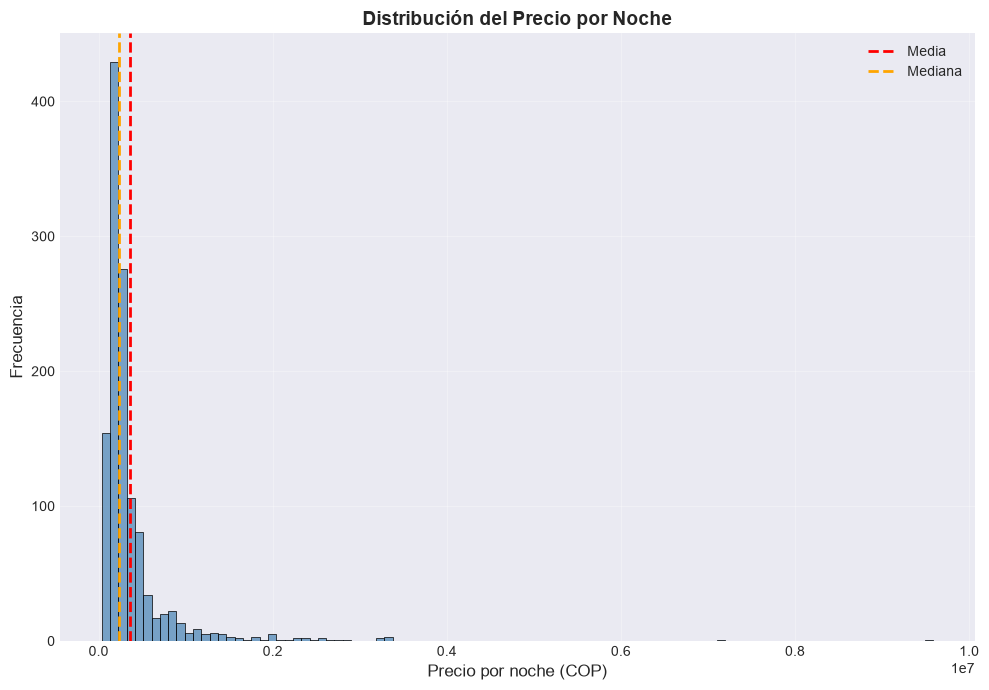

In [7]:
plt.figure(figsize=(10, 7))
sns.histplot(df['price_per_night'], bins=100, alpha=0.7, color='steelblue', edgecolor='black')
plt.axvline(df['price_per_night'].mean(), color='red', linestyle='--', linewidth=2, label='Media')
plt.axvline(df['price_per_night'].median(), color='orange', linestyle='--', linewidth=2, label='Mediana')
plt.xlabel('Precio por noche (COP)', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.title('Distribución del Precio por Noche', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La distribución tiene una cola derecha muy larga: unos pocos anuncios de lujo (fincas, penthouses) distorsionan la escala y hacen que la media quede bastante por encima de la mediana. Recortemos al percentil 95 para ver la forma del grueso del mercado.

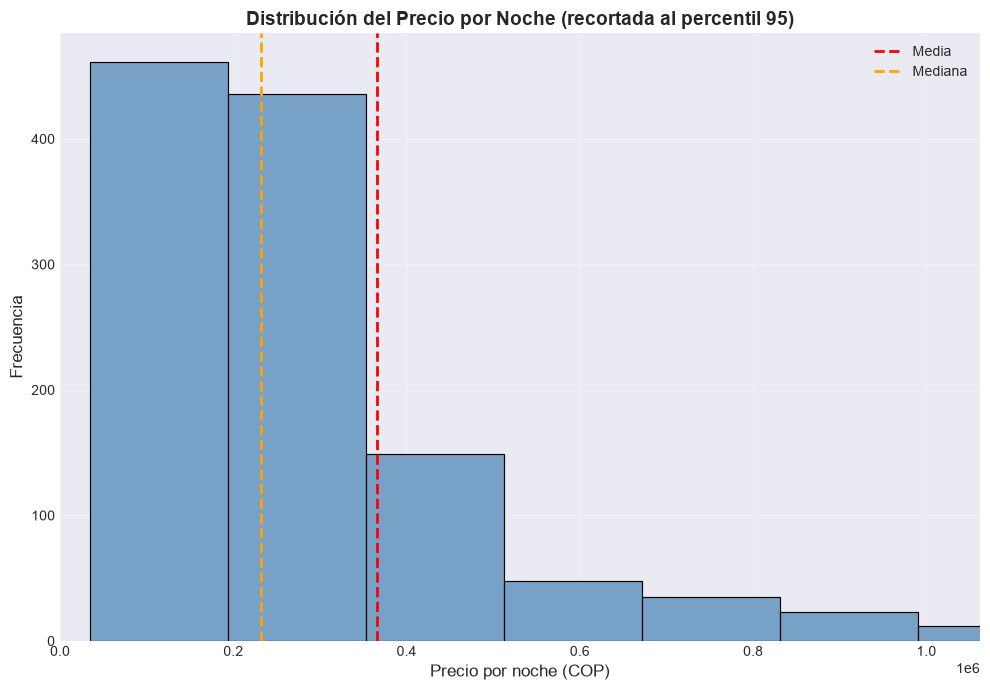

In [8]:
plt.figure(figsize=(10, 7))
sns.histplot(df['price_per_night'], bins=60, alpha=0.7, color='steelblue', edgecolor='black')
plt.axvline(df['price_per_night'].mean(), color='red', linestyle='--', linewidth=2, label='Media')
plt.axvline(df['price_per_night'].median(), color='orange', linestyle='--', linewidth=2, label='Mediana')
plt.xlabel('Precio por noche (COP)', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.title('Distribución del Precio por Noche (recortada al percentil 95)', fontsize=14, fontweight='bold')
plt.xlim(0, df['price_per_night'].quantile(0.95))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

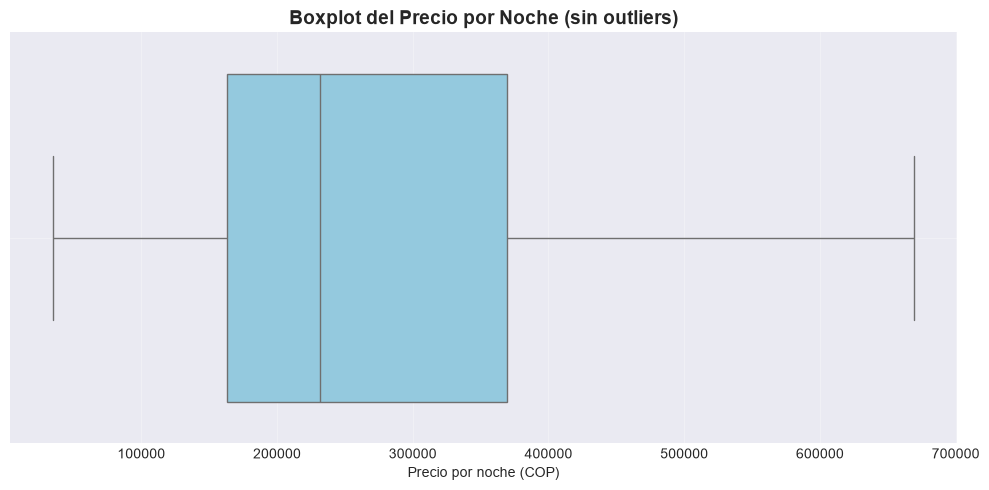

In [9]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['price_per_night'], color='skyblue', showfliers=False)
plt.xlabel('Precio por noche (COP)')
plt.title('Boxplot del Precio por Noche (sin outliers)', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

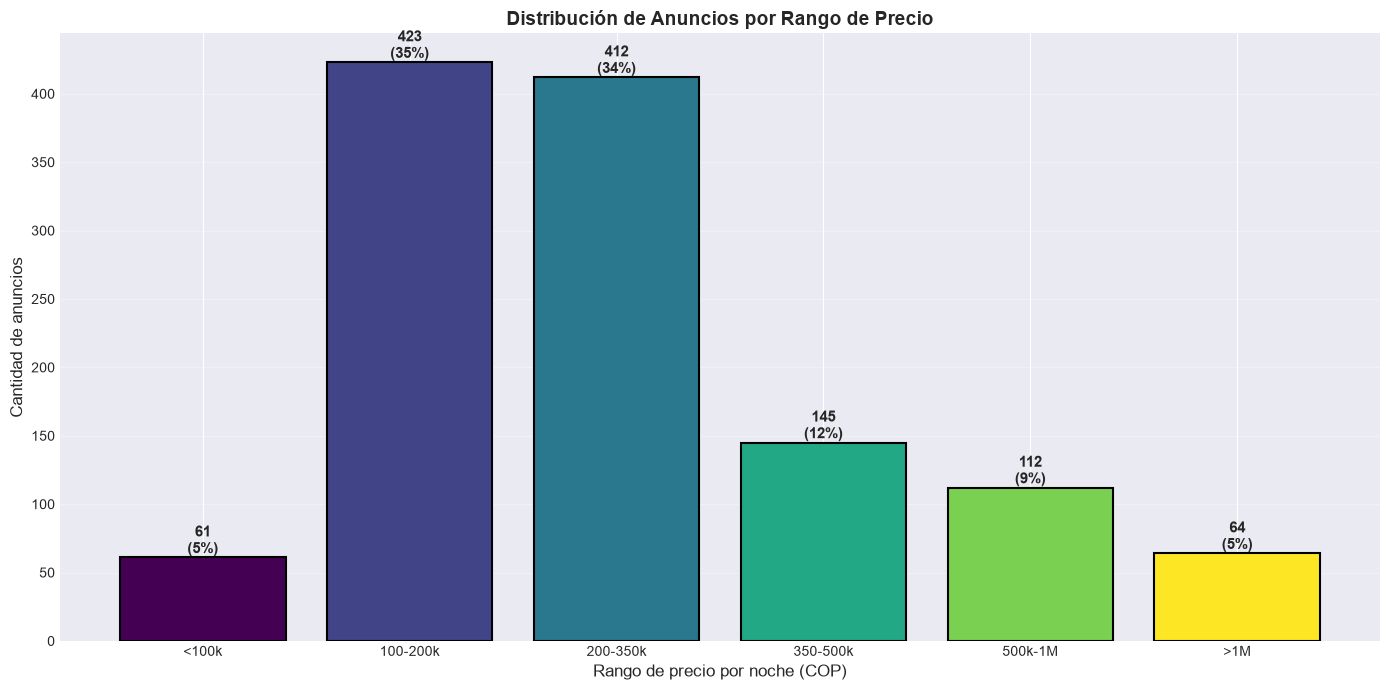

In [10]:
bins = [0, 100e3, 200e3, 350e3, 500e3, 1e6, df['price_per_night'].max() + 1]
labels = ['<100k', '100-200k', '200-350k', '350-500k', '500k-1M', '>1M']
df['price_range'] = pd.cut(df['price_per_night'], bins=bins, labels=labels)
value_counts = df['price_range'].value_counts().sort_index()

plt.figure(figsize=(14, 7))
colors = plt.cm.viridis(np.linspace(0, 1, len(value_counts)))
bars = plt.bar(value_counts.index, value_counts.values, color=colors, edgecolor='black', linewidth=1.5)
for bar, v in zip(bars, value_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, v, f'{v}\n({v/len(df):.0%})', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.xlabel('Rango de precio por noche (COP)', fontsize=12)
plt.ylabel('Cantidad de anuncios', fontsize=12)
plt.title('Distribución de Anuncios por Rango de Precio', fontsize=14, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## Tipo de alojamiento

El campo `title` que entrega Airbnb tiene la forma "Apartamento en Medellín", "Habitación en Laureles - Estadio", etc. Extraemos el tipo (la primera palabra) y la zona (lo que sigue a "en") para ver cómo varía el precio.

In [11]:
df['tipo'] = df['title'].str.extract(r'^(\w+)')[0]
df['zona'] = df['title'].str.extract(r' en (.+)$')[0]

tipo_stats = df.groupby('tipo')['price_per_night'].agg(['count', 'median', 'mean']).sort_values('count', ascending=False)
tipo_stats.head(10)

,count,median,mean
tipo,,,
Apartamento,472,"192,400.00","274,319.57"
Habitación,226,"161,025.00","233,326.79"
Cabaña,176,"361,543.00","419,029.40"
Vivienda,84,"419,643.00","832,725.86"
Loft,81,"203,809.50","216,210.98"
Casa,61,"402,500.00","608,690.59"
Minicasa,27,"270,000.00","307,595.37"
Habitaciones,22,"153,475.00","288,745.09"
Apto,19,"287,556.00","325,884.29"


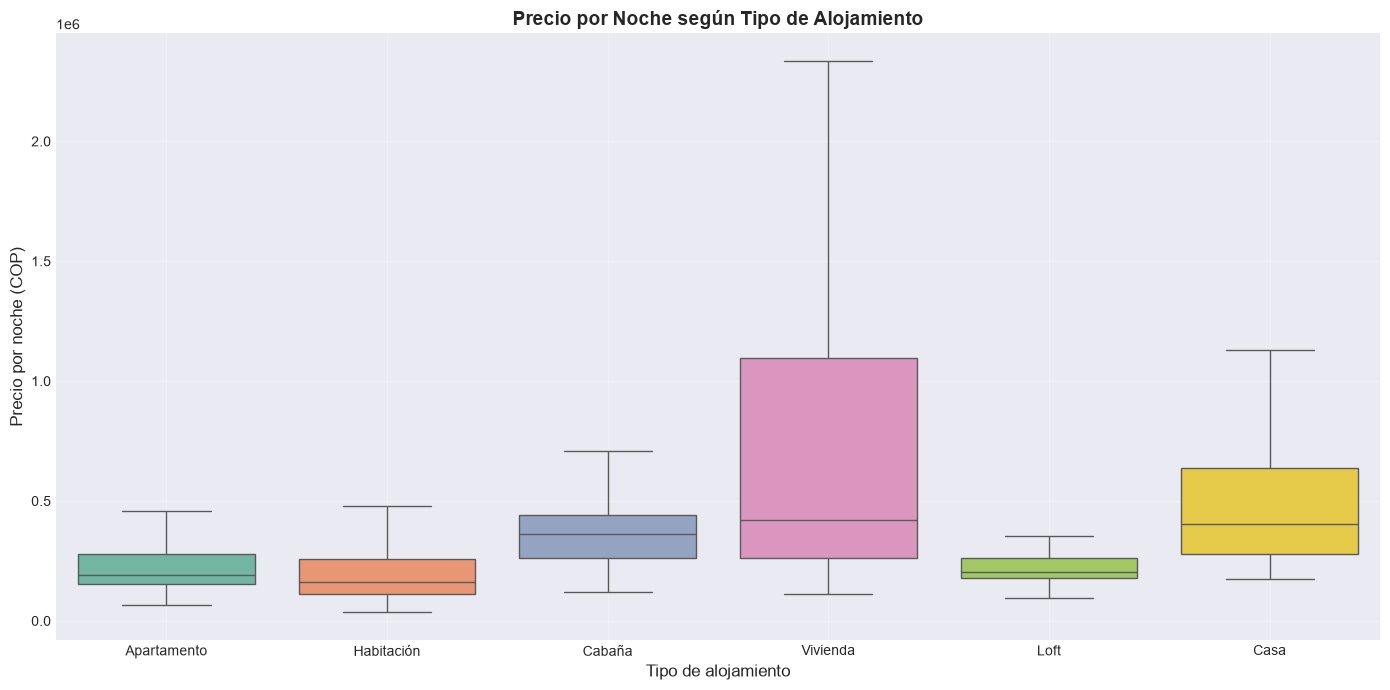

In [12]:
top_tipos = tipo_stats.head(6).index
plt.figure(figsize=(14, 7))
sns.boxplot(data=df[df['tipo'].isin(top_tipos)], x='tipo', y='price_per_night', order=top_tipos, showfliers=False, palette='Set2')
plt.xlabel('Tipo de alojamiento', fontsize=12)
plt.ylabel('Precio por noche (COP)', fontsize=12)
plt.title('Precio por Noche según Tipo de Alojamiento', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

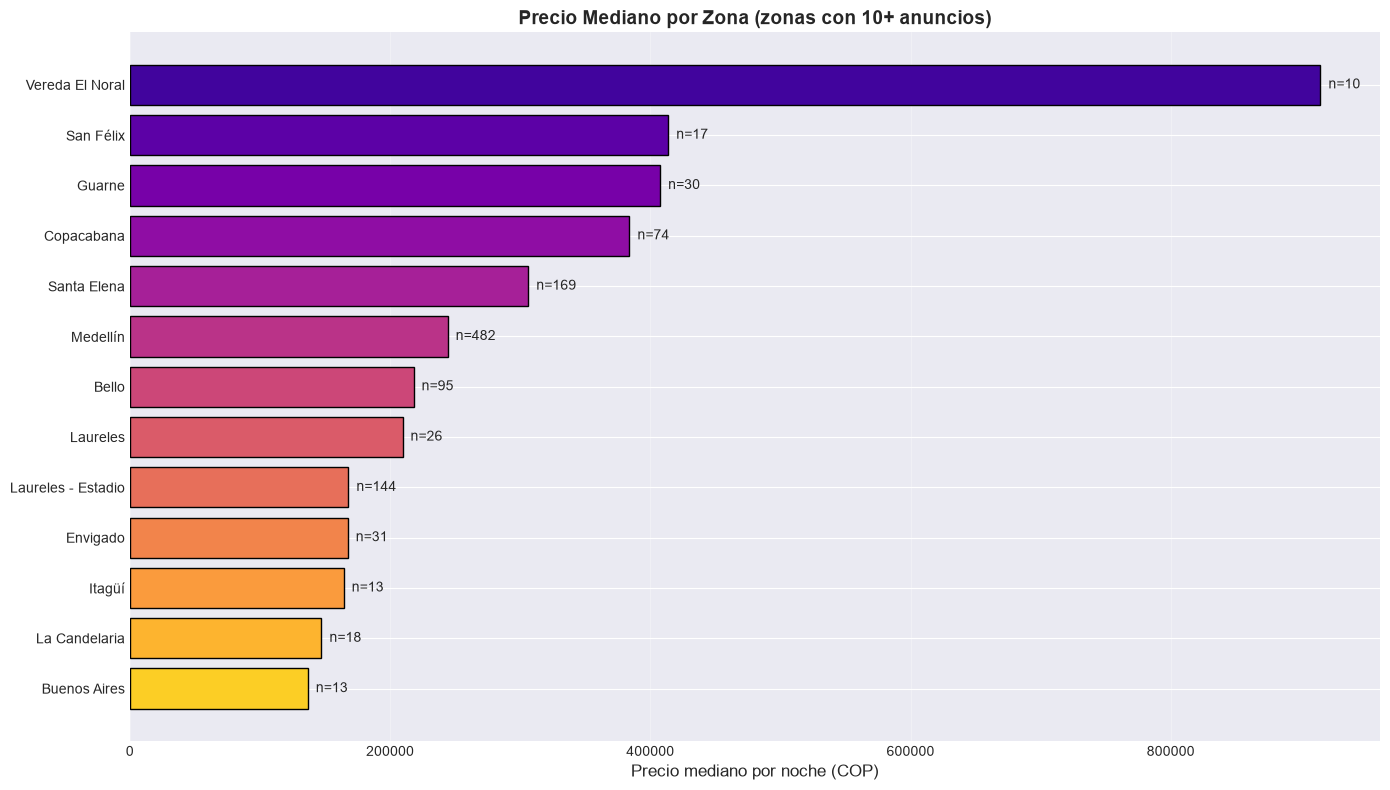

In [13]:
zona_stats = df.groupby('zona')['price_per_night'].agg(['count', 'median']).query('count >= 10').sort_values('median', ascending=False)

plt.figure(figsize=(14, 8))
plt.barh(zona_stats.index, zona_stats['median'], color=plt.cm.plasma(np.linspace(0.1, 0.9, len(zona_stats))), edgecolor='black')
for i, (n, m) in enumerate(zip(zona_stats['count'], zona_stats['median'])):
    plt.text(m, i, f'  n={n}', va='center', fontsize=10)
plt.xlabel('Precio mediano por noche (COP)', fontsize=12)
plt.title('Precio Mediano por Zona (zonas con 10+ anuncios)', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## Rating y reseñas

Ahora miramos la reputación de los anuncios: el rating (1 a 5) y la cantidad de reseñas. Solo consideramos anuncios con al menos una reseña.

Anuncios con reseñas: 842
Rating promedio: 4.823 | Mediana: 4.87
Reseñas promedio: 69.9 | Mediana: 36 | Máx: 4028
Anuncios con rating perfecto (5.0): 149 (17.7%)


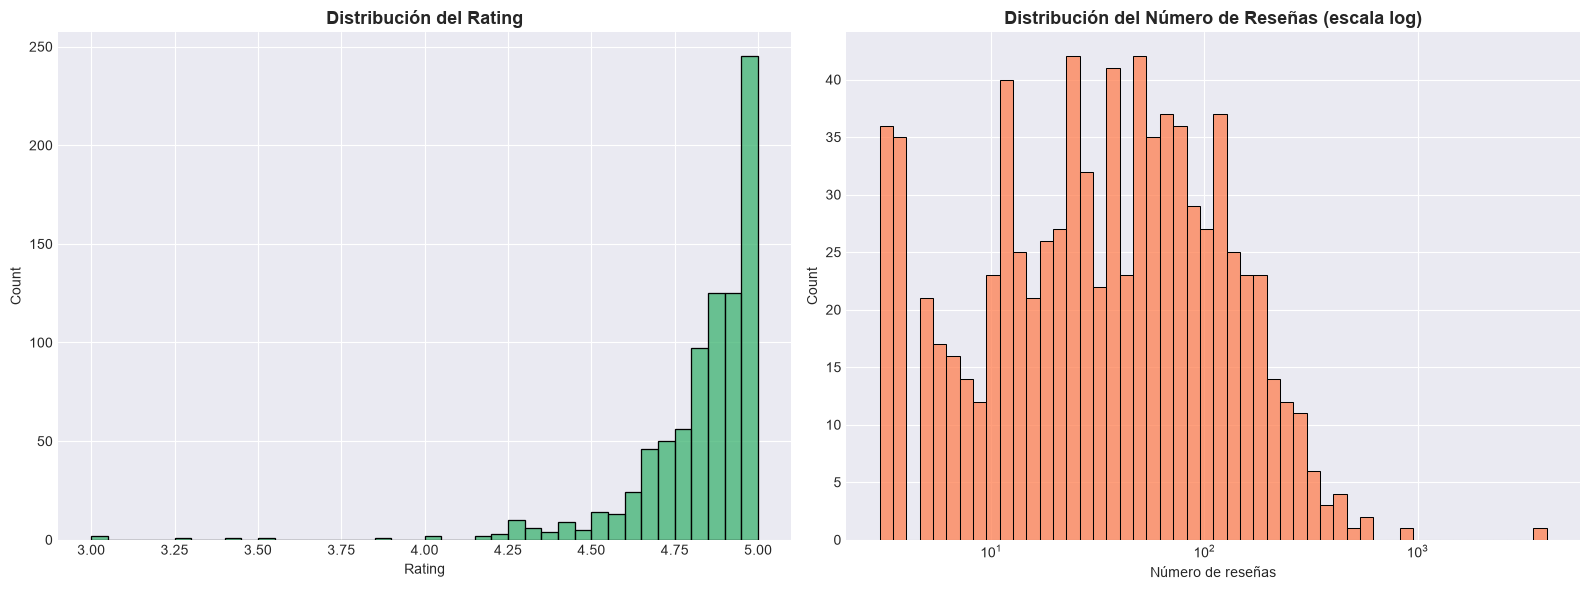

In [14]:
rated = df[df['review_count'] > 0].copy()
print(f"Anuncios con reseñas: {len(rated)}")
print(f"Rating promedio: {rated['rating'].mean():.3f} | Mediana: {rated['rating'].median():.2f}")
print(f"Reseñas promedio: {rated['review_count'].mean():.1f} | Mediana: {rated['review_count'].median():.0f} | Máx: {rated['review_count'].max()}")
print(f"Anuncios con rating perfecto (5.0): {(rated['rating'] == 5).sum()} ({(rated['rating'] == 5).mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(rated['rating'], bins=40, color='mediumseagreen', edgecolor='black', ax=axes[0])
axes[0].set_title('Distribución del Rating', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Rating')
sns.histplot(rated['review_count'], bins=50, color='coral', edgecolor='black', log_scale=True, ax=axes[1])
axes[1].set_title('Distribución del Número de Reseñas (escala log)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Número de reseñas')
plt.tight_layout()
plt.show()

El rating está fuertemente concentrado entre 4.7 y 5.0: en Airbnb prácticamente todo lo que sobrevive tiene buen rating, así que la diferencia entre un 4.8 y un 5.0 es poco informativa por sí sola. Esto justifica que el score use un **promedio bayesiano**: un 5.0 con 3 reseñas debería valer menos que un 4.9 con 200.

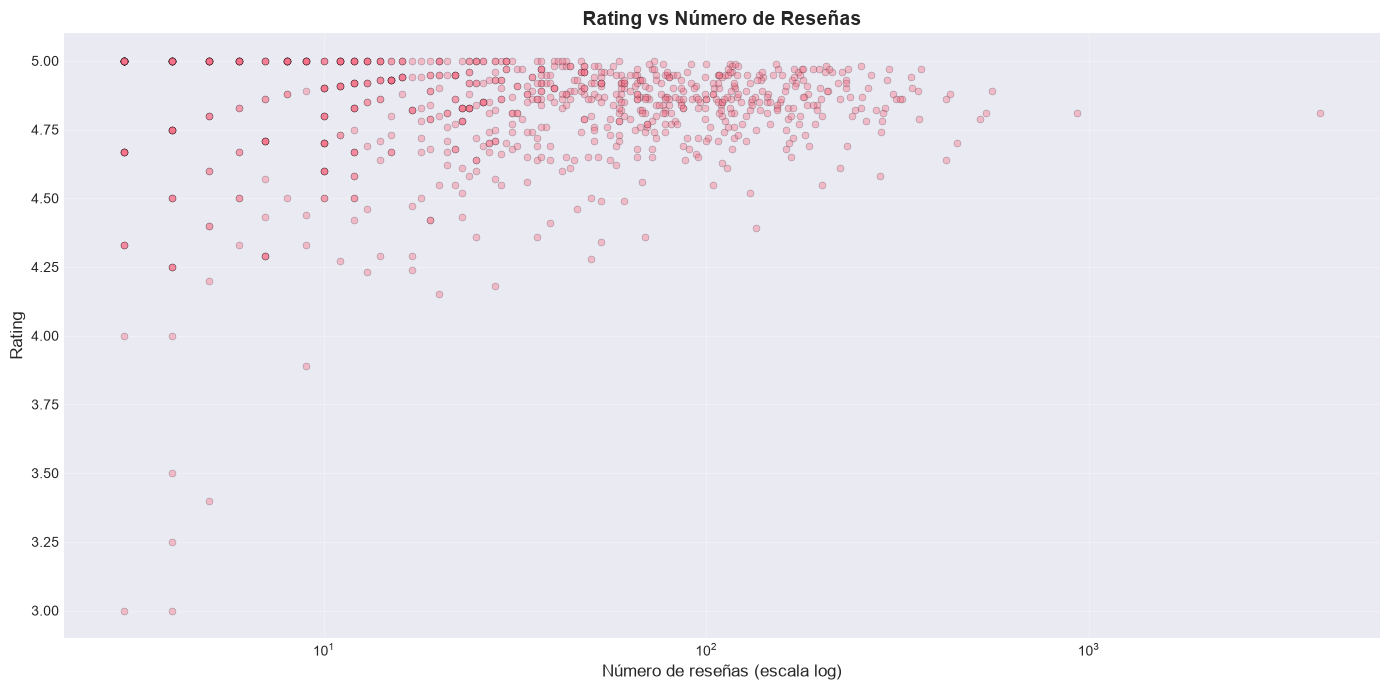

In [15]:
plt.figure(figsize=(14, 7))
plt.scatter(rated['review_count'], rated['rating'], alpha=0.4, s=25, edgecolors='black', linewidth=0.3)
plt.xscale('log')
plt.xlabel('Número de reseñas (escala log)', fontsize=12)
plt.ylabel('Rating', fontsize=12)
plt.title('Rating vs Número de Reseñas', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Se observa el patrón clásico: con pocas reseñas el rating es muy volátil (hay 5.0 y también 3.0), y a medida que crece el número de reseñas el rating converge hacia ~4.8-4.9.

## ANÁLISIS DE CORRELACIÓN

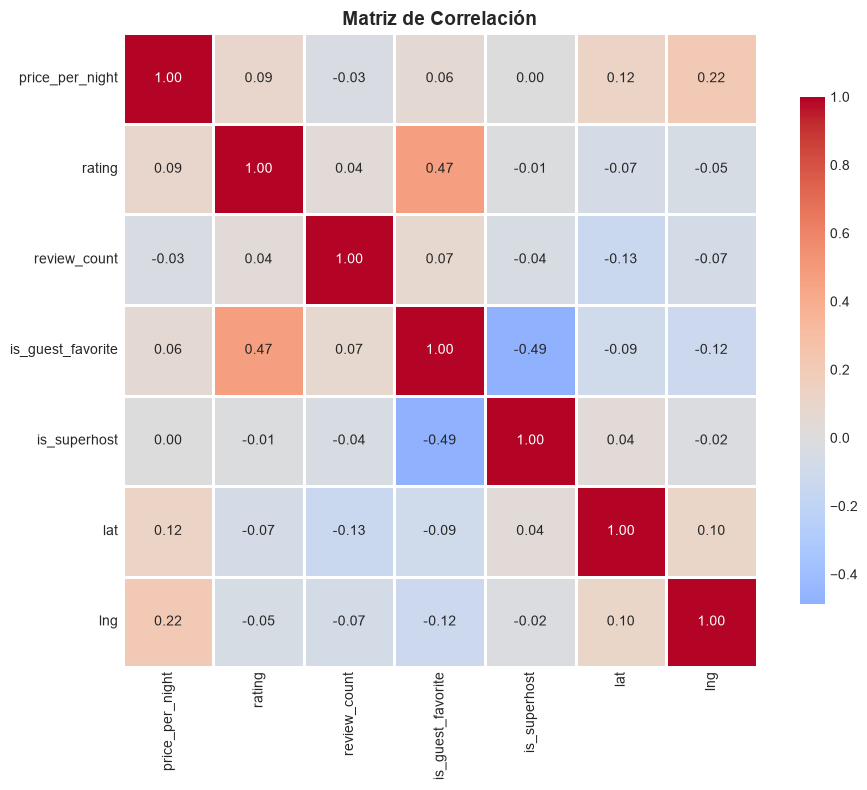

In [16]:
num_vars = ['price_per_night', 'rating', 'review_count', 'is_guest_favorite', 'is_superhost', 'lat', 'lng']
corr_matrix = rated[num_vars].astype(float).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Matriz de Correlación', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Las correlaciones lineales con el precio son prácticamente nulas (todas con |r| < 0.1). Esto es esperable: el precio depende mucho más del tipo de alojamiento (habitación vs casa entera), la capacidad y la zona, que de la reputación. La relación con el número de reseñas es ligeramente negativa y se ve mejor en el análisis bivariado siguiente: el precio mediano baja de forma monótona a medida que crecen las reseñas, porque los anuncios baratos se reservan más.

## ANÁLISIS BIVARIADOS

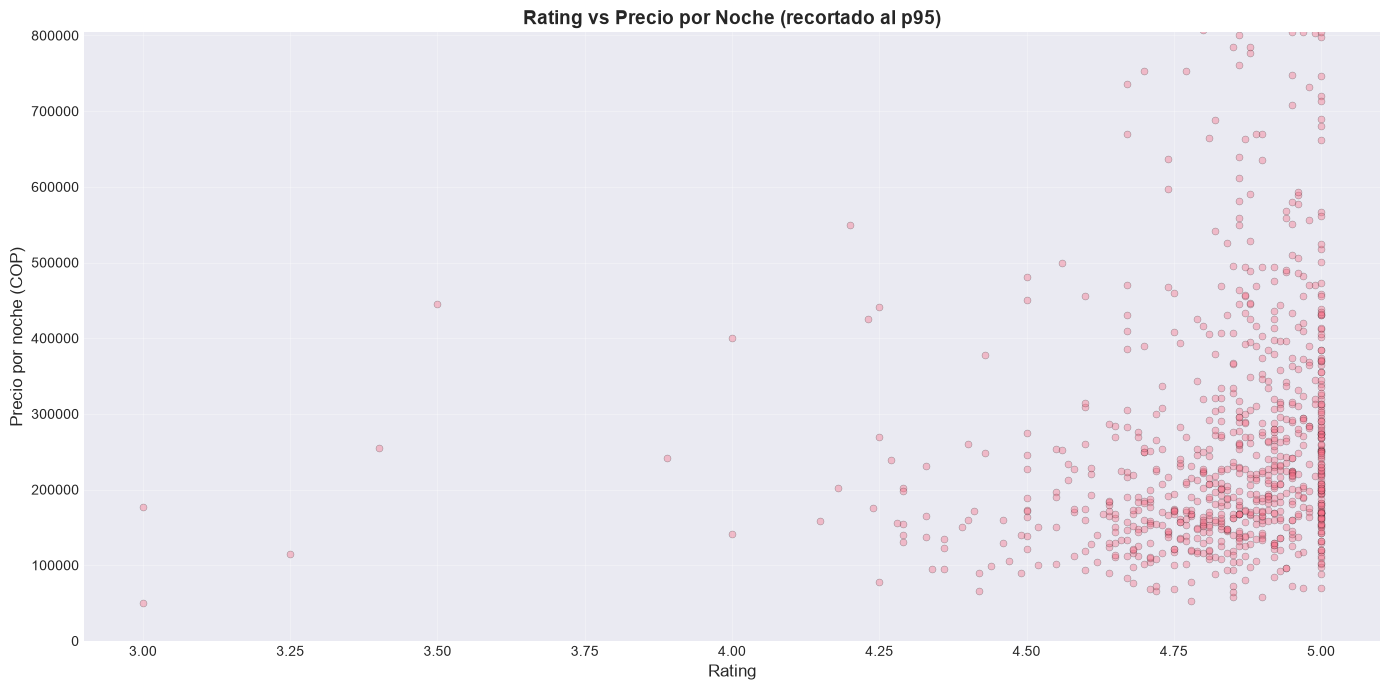

In [17]:
# Precio vs Rating
plt.figure(figsize=(14, 7))
plt.scatter(rated['rating'], rated['price_per_night'], alpha=0.4, s=25, edgecolors='black', linewidth=0.3)
plt.ylim(0, rated['price_per_night'].quantile(0.95))
plt.xlabel('Rating', fontsize=12)
plt.ylabel('Precio por noche (COP)', fontsize=12)
plt.title('Rating vs Precio por Noche (recortado al p95)', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

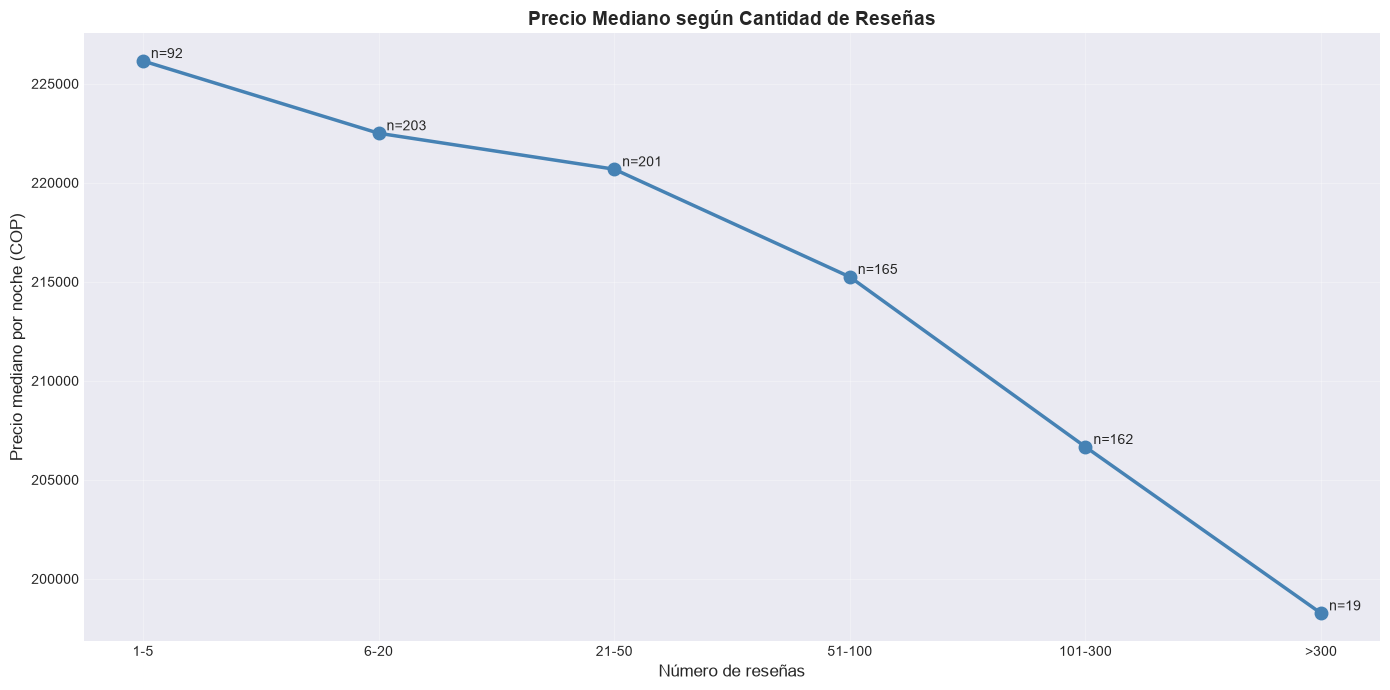

In [18]:
# Precio mediano por rango de reseñas
bins_r = [0, 5, 20, 50, 100, 300, rated['review_count'].max() + 1]
labels_r = ['1-5', '6-20', '21-50', '51-100', '101-300', '>300']
rated['review_range'] = pd.cut(rated['review_count'], bins=bins_r, labels=labels_r)
rev_price = rated.groupby('review_range')['price_per_night'].agg(['median', 'count'])

plt.figure(figsize=(14, 7))
plt.plot(rev_price.index.astype(str), rev_price['median'], marker='o', linewidth=2.5, markersize=9, color='steelblue')
for i, (m, n) in enumerate(zip(rev_price['median'], rev_price['count'])):
    plt.text(i, m, f'  n={n}', fontsize=10, va='bottom')
plt.xlabel('Número de reseñas', fontsize=12)
plt.ylabel('Precio mediano por noche (COP)', fontsize=12)
plt.title('Precio Mediano según Cantidad de Reseñas', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Guest Favorite: mediana sin=201,726 | con=224,422 | share=52%
Superhost: mediana sin=216,346 | con=225,000 | share=18%


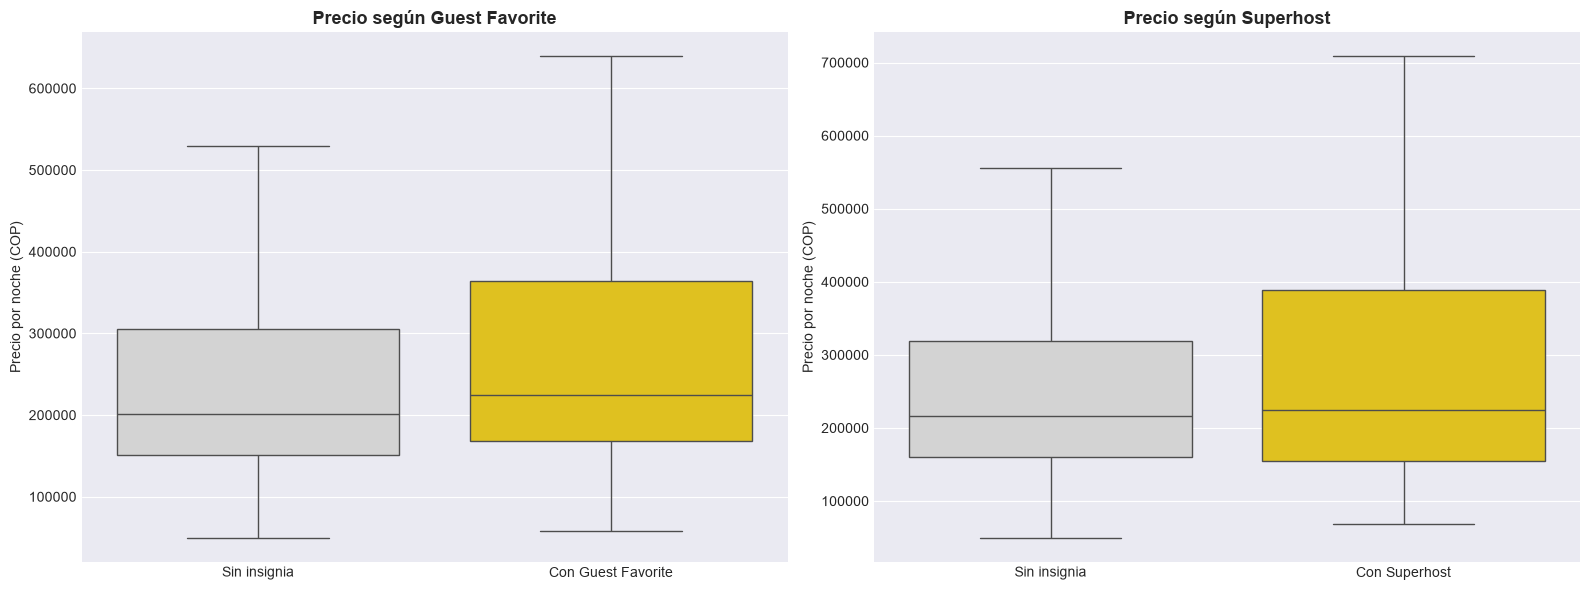

In [19]:
# Insignias vs precio
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, name in zip(axes, ['is_guest_favorite', 'is_superhost'], ['Guest Favorite', 'Superhost']):
    sns.boxplot(data=rated, x=col, y='price_per_night', showfliers=False, palette=['lightgray', 'gold'], ax=ax)
    ax.set_xticklabels(['Sin insignia', f'Con {name}'])
    ax.set_xlabel('')
    ax.set_ylabel('Precio por noche (COP)')
    ax.set_title(f'Precio según {name}', fontsize=13, fontweight='bold')
    meds = rated.groupby(col)['price_per_night'].median()
    print(f"{name}: mediana sin={meds.get(False, np.nan):,.0f} | con={meds.get(True, np.nan):,.0f} | share={rated[col].mean():.0%}")
plt.tight_layout()
plt.show()

Guest Favorite es una insignia muy extendida en Medellín (más de la mitad de los anuncios con reseñas la tienen), así que discrimina poco en precio. Superhost es más escasa y tampoco se traduce en un sobreprecio claro: la reputación no se cobra, se compite por ella.

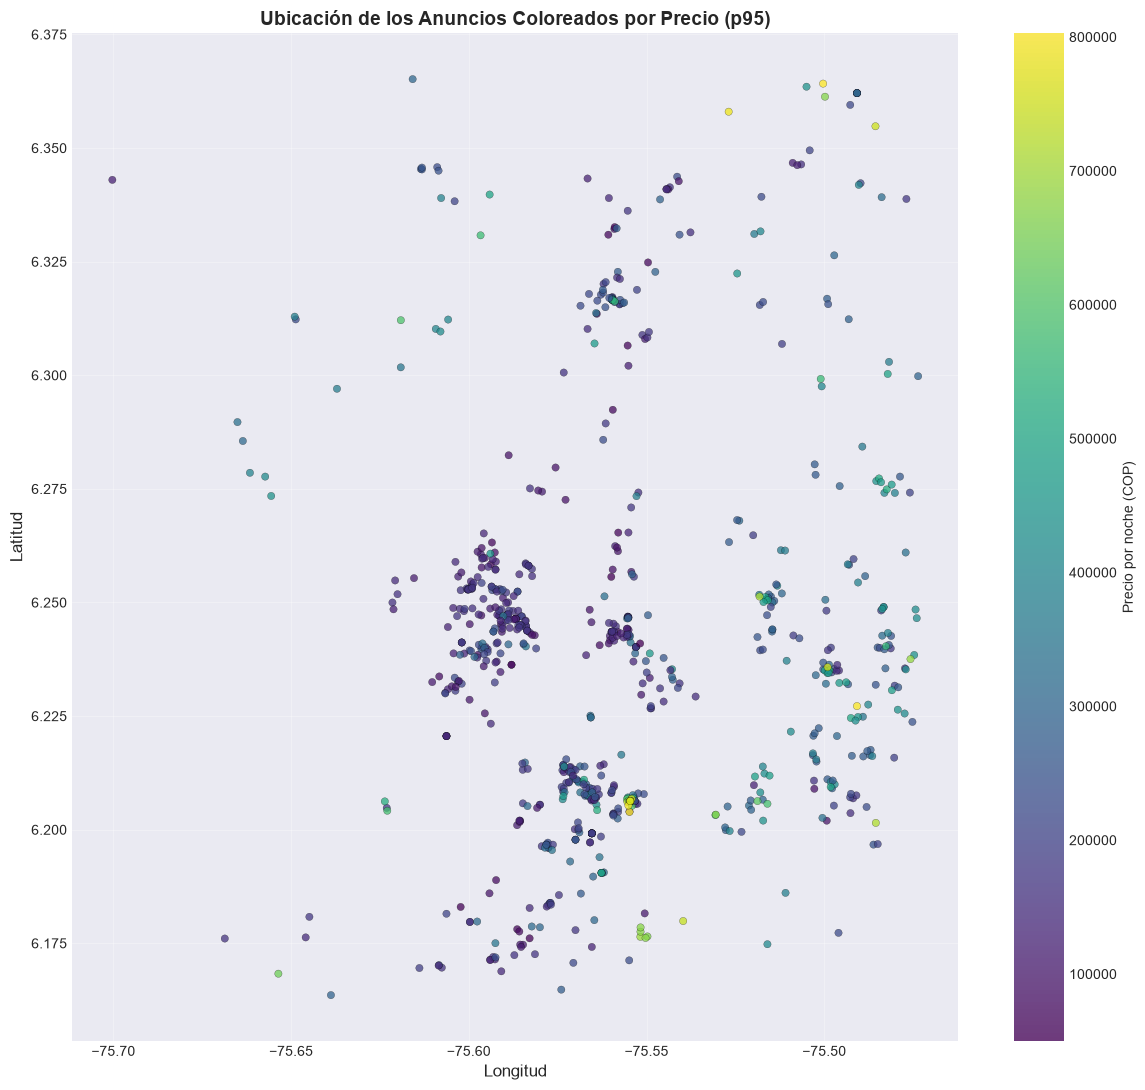

In [20]:
# Mapa: dónde están los anuncios y cuánto cuestan
plt.figure(figsize=(12, 11))
sub = rated[rated['price_per_night'] <= rated['price_per_night'].quantile(0.95)]
sc = plt.scatter(sub['lng'], sub['lat'], c=sub['price_per_night'], cmap='viridis', s=28, alpha=0.75, edgecolors='black', linewidth=0.2)
plt.colorbar(sc, label='Precio por noche (COP)')
plt.xlabel('Longitud', fontsize=12)
plt.ylabel('Latitud', fontsize=12)
plt.title('Ubicación de los Anuncios Coloreados por Precio (p95)', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La oferta urbana se concentra en el valle (Laureles-Estadio, centro, Envigado, Itagüí) y es la más barata: medianas entre 140 mil y 210 mil COP por noche. Los precios más altos aparecen hacia el oriente y el norte (Santa Elena, Guarne, Copacabana, San Félix), donde predominan fincas y cabañas de campo con capacidad para grupos. Nota: el bounding box que Nominatim devuelve para "Medellín" abarca municipios vecinos del Valle de Aburrá y el oriente cercano, por eso aparecen en el dataset.

# PARTE 2: SCORE PONDERADO Y MEJORES PROPIEDADES

El scraper calcula el score con la función `airbnb_scraper.score.score`, que aquí reutilizamos. La fórmula:

- **price_score** = 1 − minmax(precio por noche recortado al p95). Más barato → más cerca de 1.
- **rating_bayes** = (n / (n + m)) · rating + (m / (n + m)) · rating_promedio, con n = número de reseñas y m = 10. Un anuncio con pocas reseñas se "arrastra" hacia la media global.
- **rating_score** = minmax(rating_bayes).
- **score** = w_precio · price_score + w_rating · rating_score, con los pesos de `config.toml` (por defecto 0.5 / 0.5).

Solo entran al ranking los anuncios que pasan los filtros (mínimo 3 reseñas).

In [21]:
cfg = load_config('../config.toml')
print("Pesos:", cfg['weights'], "| Filtros:", cfg['filters'])

ranked = score(apply_filters(df, cfg['filters']), cfg)
top15 = ranked.head(15)[['rank', 'name', 'title', 'details', 'price_per_night', 'rating', 'review_count', 'score', 'url']]
top15.style.format({'price_per_night': '${:,.0f}', 'score': '{:.3f}', 'rating': '{:.2f}'}).hide(axis='index')

Pesos: {'price': 0.5, 'rating': 0.5} | Filtros: {'min_reviews': 3, 'min_rating': 0.0, 'max_price_per_night': 0}


rank,name,title,details,price_per_night,rating,review_count,score,url
1,Habitación independiente baño privado Estadio 5min,Habitación en Laureles - Estadio,1 cama doble · 1 baño,"$70,000",4.97,301,0.976,https://www.airbnb.com/rooms/893731397152782835?check_in=2026-11-14&check_out=2026-11-16
2,"Habitación amplia, cama king baño privado Laureles",Habitación en Laureles - Estadio,1 cama · 2 baños,"$72,000",4.95,107,0.955,https://www.airbnb.com/rooms/938572123202186100?check_in=2026-11-14&check_out=2026-11-16
3,Laureles-Estadio Suite•Baño Privado•Metro•900Mb-WS,Habitación en Laureles - Estadio,1 cama doble · 1 baño,"$101,121",5.00,36,0.953,https://www.airbnb.com/rooms/1580035115689647558?check_in=2026-11-14&check_out=2026-11-16
4,Estadio Home Shelter - Habitación 3,Habitación en Laureles - Estadio,"1 cama · 1,5 baños","$130,000",5.00,59,0.943,https://www.airbnb.com/rooms/1323508571653898164?check_in=2026-11-14&check_out=2026-11-16
5,Apartamento zona central Medellín.,Apartamento en Robledo,2 dormitorios · 3 camas · 1 baño,"$96,500",4.94,141,0.934,https://www.airbnb.com/rooms/601665011169061321?check_in=2026-11-14&check_out=2026-11-16
6,Buena Vista. Tranquilidad en un ambiente de campo.,Habitación en Santa Elena,1 sofá cama · 1 baño,"$95,870",4.94,80,0.931,https://www.airbnb.com/rooms/40748511?check_in=2026-11-14&check_out=2026-11-16
7,Habitación privada | Laureles–Estadio | WiFi,Habitación en Laureles - Estadio,1 cama doble · 1 baño,"$88,706",5.00,11,0.927,https://www.airbnb.com/rooms/1781232434842399188?check_in=2026-11-14&check_out=2026-11-16
8,"Habitación en Itagüi, Colombia",Habitación en Itagüí,1 cama doble pequeña · 1 baño,"$57,760",4.90,40,0.925,https://www.airbnb.com/rooms/1109713945641008314?check_in=2026-11-14&check_out=2026-11-16
9,Luz Natural Apartaestudio Laureles,Apartamento en Laureles - Estadio,1 dormitorio · 1 cama doble · 1 baño,"$118,000",4.97,37,0.925,https://www.airbnb.com/rooms/919087236820687910?check_in=2026-11-14&check_out=2026-11-16
10,Habitación con vista a la ciudad/ excelente ubi,Habitación en Robledo,1 cama doble · Sin baño,"$92,090",4.93,45,0.921,https://www.airbnb.com/rooms/981521082640013002?check_in=2026-11-14&check_out=2026-11-16


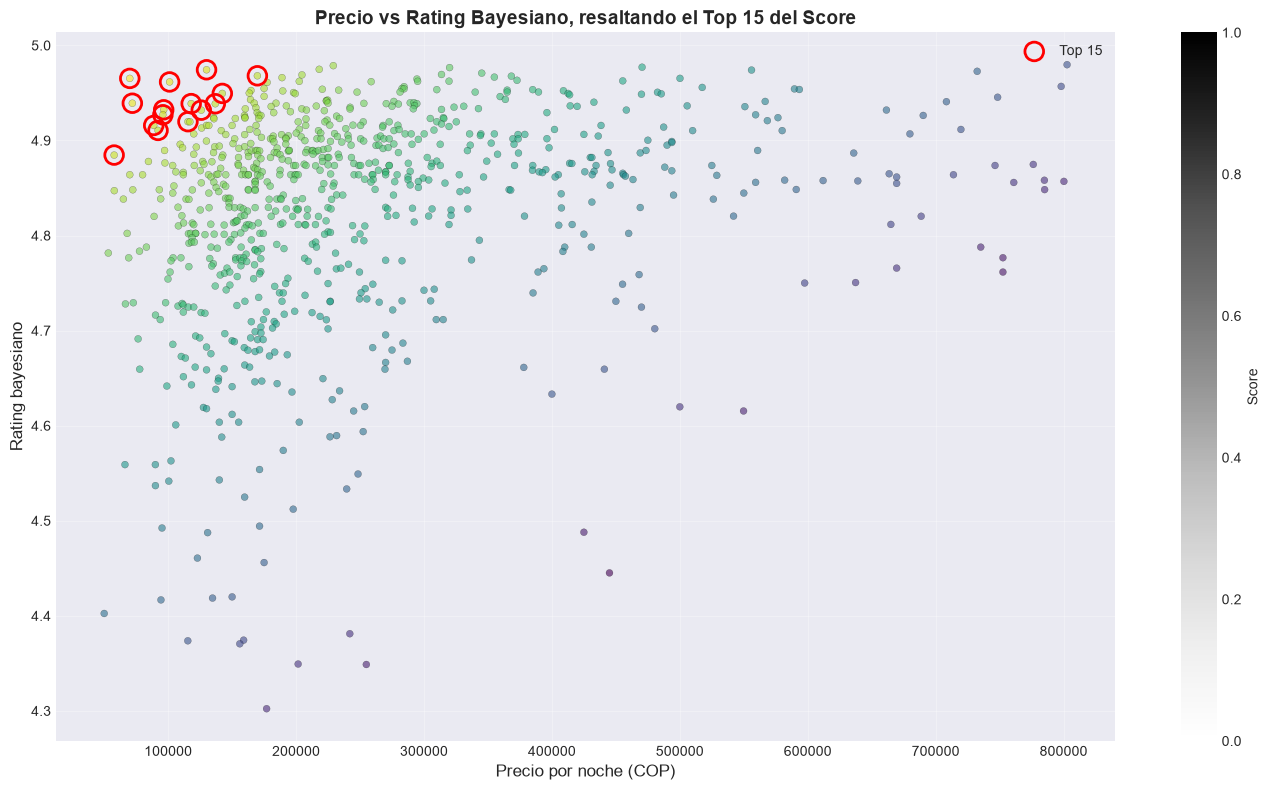

In [22]:
plt.figure(figsize=(14, 8))
base = ranked[ranked['price_per_night'] <= ranked['price_per_night'].quantile(0.95)]
plt.scatter(base['price_per_night'], base['rating_bayes'], c=base['score'], cmap='viridis', s=25, alpha=0.6, edgecolors='black', linewidth=0.2)
top = ranked.head(15)
plt.scatter(top['price_per_night'], top['rating_bayes'], s=180, facecolors='none', edgecolors='red', linewidth=2, label='Top 15')
plt.colorbar(label='Score')
plt.xlabel('Precio por noche (COP)', fontsize=12)
plt.ylabel('Rating bayesiano', fontsize=12)
plt.title('Precio vs Rating Bayesiano, resaltando el Top 15 del Score', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

El top 15 se ubica en la esquina ideal: precio bajo y rating bayesiano alto. Como el rating está tan comprimido, en la práctica el score con pesos 50/50 favorece anuncios baratos (habitaciones privadas y apartaestudios) que además tienen un historial sólido de reseñas.

## Sensibilidad a los pesos

¿Qué tanto cambia el ranking si alguien valora más la reputación que el precio, o al revés? Recalculamos el top 10 con tres configuraciones y medimos cuántos anuncios se mantienen.

Anuncios del top 10 default que se mantienen en cada escenario:
  70% precio / 30% rating: 8/10
  50% / 50% (default): 10/10
  30% precio / 70% rating: 6/10


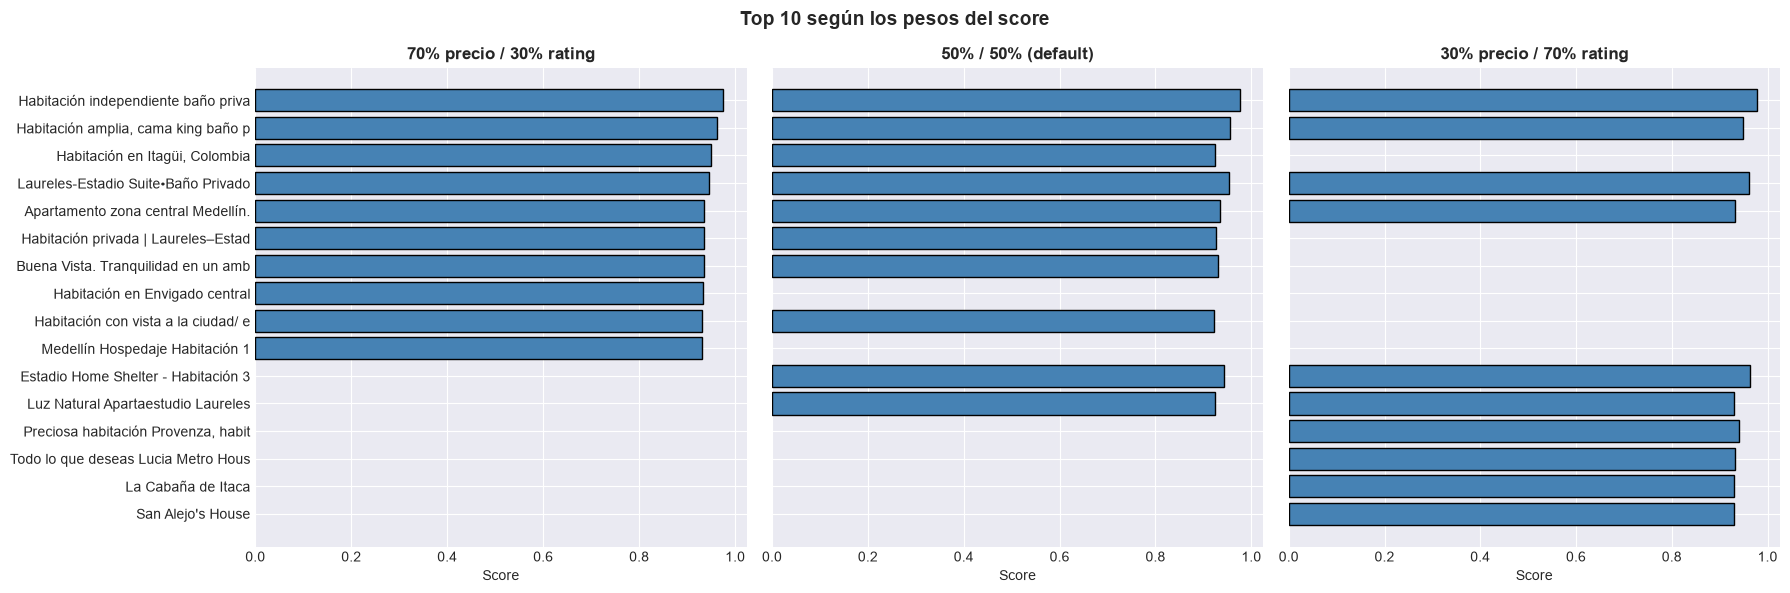

In [23]:
def top_ids(w_price, w_rating, n=10):
    c = {**cfg, 'weights': {'price': w_price, 'rating': w_rating}}
    return set(score(apply_filters(df, cfg['filters']), c).head(n)['room_id'])

escenarios = {'70% precio / 30% rating': (0.7, 0.3), '50% / 50% (default)': (0.5, 0.5), '30% precio / 70% rating': (0.3, 0.7)}
tops = {k: top_ids(*v) for k, v in escenarios.items()}
base_top = tops['50% / 50% (default)']

print("Anuncios del top 10 default que se mantienen en cada escenario:")
for k, ids in tops.items():
    print(f"  {k}: {len(ids & base_top)}/10")

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, (k, (wp, wr)) in zip(axes, escenarios.items()):
    c = {**cfg, 'weights': {'price': wp, 'rating': wr}}
    t = score(apply_filters(df, cfg['filters']), c).head(10)
    ax.barh(t['name'].str.slice(0, 35), t['score'], color='steelblue', edgecolor='black')
    ax.invert_yaxis()
    ax.set_title(k, fontsize=12, fontweight='bold')
    ax.set_xlabel('Score')
plt.suptitle('Top 10 según los pesos del score', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Conclusiones del Proyecto

El objetivo fue construir una base de datos propia de anuncios de Airbnb en Medellín para unas fechas concretas, explorar qué explica el precio por noche y proponer un ranking ponderado que ayude a decidir dónde quedarse.

**Sobre el precio.** La distribución del precio por noche es muy asimétrica: la mayoría de los anuncios cuesta entre 100 mil y 350 mil COP, pero una cola de fincas y apartamentos de lujo eleva la media muy por encima de la mediana. El tipo de alojamiento (habitación vs apartamento vs casa) y la zona explican mucho más del precio que la reputación: las zonas más caras no son las urbanas sino las rurales del oriente (fincas en Santa Elena, Guarne, Copacabana), mientras que Laureles-Estadio, Envigado e Itagüí son las más baratas; las correlaciones lineales de precio con rating e insignias son prácticamente nulas, y la única relación consistente es negativa con el número de reseñas (lo barato se reserva más y acumula más reseñas).

**Sobre la reputación.** El rating en Airbnb está comprimido entre 4.7 y 5.0, por lo que por sí solo discrimina poco. Combinarlo con el número de reseñas mediante un promedio bayesiano resuelve el problema de los anuncios nuevos con 5.0 y 2 reseñas, y da un ordenamiento más confiable. Las insignias Guest Favorite y Superhost no implican un sobreprecio.

**Sobre el score.** Con pesos 50/50, el top del ranking lo dominan habitaciones privadas y apartaestudios baratos con decenas de reseñas y rating casi perfecto, principalmente en Laureles-Estadio. El ranking es razonablemente estable al mover los pesos: la mayoría del top 10 se mantiene al pasar a 70/30 o 30/70, lo que indica que hay un grupo de anuncios que son buenos en ambas dimensiones y no solo en una.

**Limitaciones.** Los datos corresponden a un único rango de fechas y una búsqueda para 2 adultos; los precios cambian con la temporada y la anticipación. El scraper depende de un API interno de Airbnb que puede cambiar o bloquear las peticiones. Como siguiente paso, se podría agregar distancia a un punto de interés como tercer factor del score, y comparar varias fechas para estudiar la estacionalidad.